# Entrainement du model.

In [3]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

I0000 00:00:1793369455.305137  493573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793369455.311799  493573 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793369455.505439  493573 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793369458.092364  493573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONE

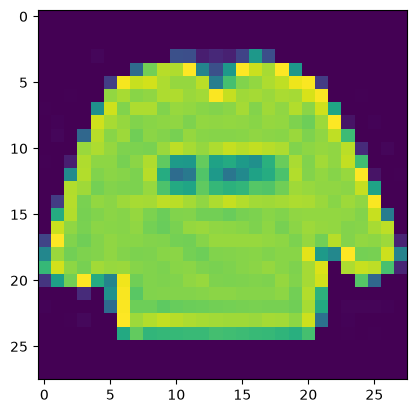

In [4]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

# Preparation des donnes

In [5]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [6]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

In [7]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

# Configuration

In [9]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

# Comparaison, apprentisage et test.

In [10]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

In [11]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.7936 - loss: 0.5797 - val_accuracy: 0.8581 - val_loss: 0.4053
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8680 - loss: 0.3730 - val_accuracy: 0.8725 - val_loss: 0.3628
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8831 - loss: 0.3285 - val_accuracy: 0.8851 - val_loss: 0.3283
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.8925 - loss: 0.3012 - val_accuracy: 0.8934 - val_loss: 0.2993
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8995 - loss: 0.2789 - val_accuracy: 0.8985 - val_loss: 0.2853
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9060 - loss: 0.2598 - val_accuracy: 0.8991 - val_loss: 0.2815
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9114 - loss: 0.2450 - val_accuracy: 0.9049 - val_loss: 0.2672
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.9178 - loss: 0.2308 - val_accu

In [12]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.24446313083171844
Précision: 0.9132999777793884


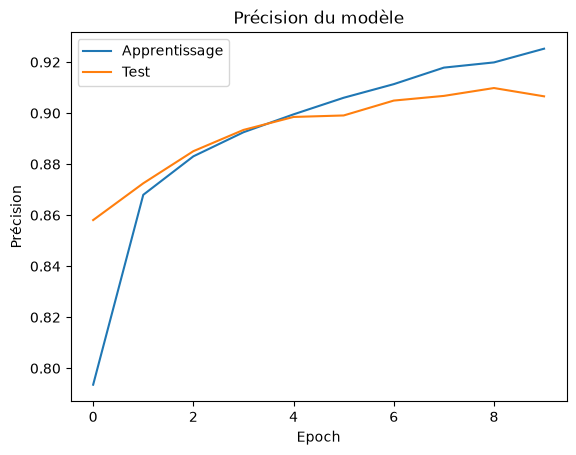

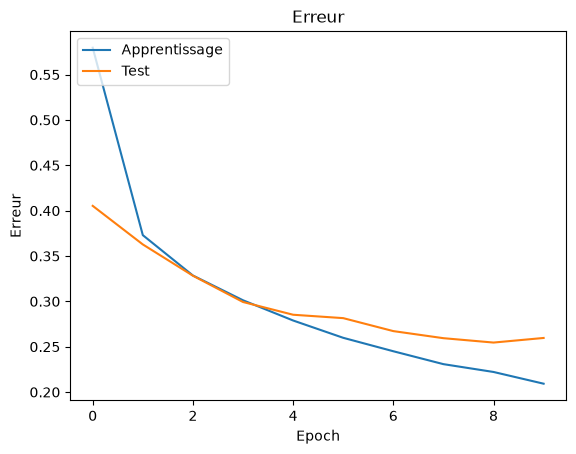

In [13]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

# Augmentation des nombres de donnes

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

In [15]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50


I0000 00:00:1793370146.634761  493573 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.8223 - loss: 0.4731 - val_accuracy: 0.8383 - val_loss: 0.4227
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.8438 - loss: 0.4401

/home/pesto/Projet/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8438 - loss: 0.4401 - val_accuracy: 0.8418 - val_loss: 0.4228
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.8462 - loss: 0.4131 - val_accuracy: 0.8495 - val_loss: 0.4063
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8320 - loss: 0.4595 - val_accuracy: 0.8516 - val_loss: 0.4054
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8527 - loss: 0.3937 - val_accuracy: 0.8593 - val_loss: 0.3774
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8359 - loss: 0.4337 - val_accuracy: 0.8612 - val_loss: 0.3779
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 62ms/step - accuracy: 0.8607 - loss: 0.3785 - val_accuracy: 0.8615 - val_loss: 0.3675
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8477 - loss: 0.4150 - val_accuracy: 0.8644 - val_loss: 0.3704
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.8617 - loss: 0.3694 - val_accuracy: 0.867

# Sauvegarde du model.

In [23]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


In [19]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/pesto/Projet/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 46s 215ms/step - accuracy: 0.7363 - loss: 0.7572 - val_accuracy: 0.1845 - val_loss: 3.4353
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 232ms/step - accuracy: 0.8394 - loss: 0.4450 - val_accuracy: 0.3768 - val_loss: 2.4479
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 231ms/step - accuracy: 0.8675 - loss: 0.3705 - val_accuracy: 0.8361 - val_loss: 0.4548
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 233ms/step - accuracy: 0.8813 - loss: 0.3361 - val_accuracy: 0.8898 - val_loss: 0.2968
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 235ms/step - accuracy: 0.8894 - loss: 0.3110 - val_accuracy: 0.9008 - val_loss: 0.2674
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 229ms/step - accuracy: 0.8965 - loss: 0.2879 - val_accuracy: 0.9042 - val_loss: 0.2591
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 229ms/step - accuracy: 0.9027 - loss: 0.2711 - val_accuracy: 0.9043 - val_loss: 0.2626
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 226ms/step - accuracy: 0.9053 - loss: 0

In [21]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.2653091847896576
Précision: 0.9065999984741211


In [22]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 45s 224ms/step - accuracy: 0.8516 - loss: 0.4092 - val_accuracy: 0.8723 - val_loss: 0.3509
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8633 - loss: 0.3842 - val_accuracy: 0.8689 - val_loss: 0.3635
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 42s 223ms/step - accuracy: 0.8700 - loss: 0.3631 - val_accuracy: 0.8874 - val_loss: 0.3024
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8789 - loss: 0.3498 - val_accuracy: 0.8867 - val_loss: 0.3089
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 43s 227ms/step - accuracy: 0.8739 - loss: 0.3476 - val_accuracy: 0.8857 - val_loss: 0.3083
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8906 - loss: 0.3130 - val_accuracy: 0.8859 - val_loss: 0.3055
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 43s 228ms/step - accuracy: 0.8806 - loss: 0.3312 - val_accuracy: 0.8956 - val_loss: 0.2874
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8984 - loss: 0.2734 - 

# Modele avec d'autres images.

In [24]:
#Chargement de la description du modèle
fichier_json = open('modele/modele.json', 'r')
modele_json = fichier_json.read()
fichier_json.close()

#Chargement de la description des poids du modèle
from keras.models import model_from_json
modele = model_from_json(modele_json)
#Chargement des poids
modele.load_weights("modele/modele.weights.h5")

In [25]:
#Définition des catégories de classifications
classes = ["Un T-shirt/haut",
           "Un pantalon",
           "Un pull", 
           "Une robe",
           "Un manteau",
           "Des sandales",
           "Une chemise",
           "Des baskets", 
           "Un sac",
           "Des bottes de cheville"]

In [26]:
import numpy as np
from PIL import Image, ImageFilter


def load_and_preprocess_image(image_path, target_size=28, content_size=20):
    """
    Load an image, convert to grayscale, and preprocess for model input.
    
    Args:
        image_path: Path to the input image
        target_size: Size of the output square image (default: 28x28)
        content_size: Size of the resized content within the target (default: 20)
    
    Returns:
        numpy.ndarray: Preprocessed image array ready for model prediction
    """
    image = Image.open(image_path).convert('L')
    resized_img = resize_with_aspect_ratio(image, content_size)
    canvas = create_centered_image(resized_img, target_size)
    normalized_array = normalize_pixels(canvas)
    
    return normalized_array.reshape(1, target_size, target_size, 1)


def resize_with_aspect_ratio(image, target_dimension):
    """
    Resize image maintaining aspect ratio.
    
    Args:
        image: PIL Image object
        target_dimension: Target size for the longest dimension
    
    Returns:
        PIL Image: Resized and sharpened image
    """
    width, height = image.size
    
    if width > height:
        new_width = target_dimension
        new_height = max(1, round(target_dimension * height / width))
    else:
        new_height = target_dimension
        new_width = max(1, round(target_dimension * width / height))
    
    return image.resize((new_width, new_height), Image.LANCZOS).filter(ImageFilter.SHARPEN)


def create_centered_image(image, canvas_size):
    """
    Place image in the center of a white canvas.
    
    Args:
        image: PIL Image to center
        canvas_size: Size of the square canvas
    
    Returns:
        PIL Image: Image centered on white canvas
    """
    canvas = Image.new('L', (canvas_size, canvas_size), 255)
    
    img_width, img_height = image.size
    
    # Calculate centering offsets
    x_offset = (canvas_size - img_width) // 2
    y_offset = (canvas_size - img_height) // 2
    
    canvas.paste(image, (x_offset, y_offset))
    return canvas


def normalize_pixels(image):
    pixels = np.array(image.getdata(), dtype=np.float32)
    # Invert colors (white background to black) and normalize
    return (255 - pixels) / 255.0

In [28]:
image_array = load_and_preprocess_image("image.png")

probabilities = modele.predict(image_array)[0]
predicted_class = np.argmax(probabilities)

print(f"Selon moi l'image est : {classes[predicted_class]}\n")

for i, class_name in enumerate(classes):
    print(f"{class_name}: {probabilities[i] * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
Selon moi l'image est : Un pantalon

Un T-shirt/haut: 0.06%
Un pantalon: 99.84%
Un pull: 0.00%
Une robe: 0.01%
Un manteau: 0.00%
Des sandales: 0.06%
Une chemise: 0.00%
Des baskets: 0.00%
Un sac: 0.03%
Des bottes de cheville: 0.00%


/tmp/ipykernel_493573/94602248.py:72: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = np.array(image.getdata(), dtype=np.float32)
